In [89]:
# improting the basic libraries
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 
import os
%matplotlib inline
warnings.filterwarnings('ignore')


# statistical analysis of variance 
from statsmodels.formula.api import ols


# missing value remover libraries
from lightgbm import LGBMClassifier, LGBMRegressor # also using this for model building
from sklearn.mixture import GaussianMixture

# Feature Engineering libraries
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, MinMaxScaler, RobustScaler
from sklearn.feature_selection import RFE, SelectKBest, chi2, f_classif, mutual_info_classif
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, StratifiedKFold, KFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import xgboost as xgb

# Tensorflow libraries
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

In [90]:
train = pd.read_csv(r'D:\House Price prediction\train.csv')
train.describe(include='all')

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
count,1460.000000,1460.000000,1460,1201.000000,1460.000000,1460,91,1460,1460,1460,...,1460.000000,7,281,54,1460.000000,1460.000000,1460.000000,1460,1460,1460.000000
unique,NaN,NaN,5,NaN,NaN,2,2,4,4,2,...,NaN,3,4,4,NaN,NaN,NaN,9,6,NaN
top,NaN,NaN,RL,NaN,NaN,Pave,Grvl,Reg,Lvl,AllPub,...,NaN,Gd,MnPrv,Shed,NaN,NaN,NaN,WD,Normal,NaN
freq,NaN,NaN,1151,NaN,NaN,1454,50,925,1311,1459,...,NaN,3,157,49,NaN,NaN,NaN,1267,1198,NaN
mean,730.500000,56.897260,NaN,70.049958,10516.828082,NaN,NaN,NaN,NaN,NaN,...,2.758904,NaN,NaN,NaN,43.489041,6.321918,2007.815753,NaN,NaN,180921.195890
std,421.610009,42.300571,NaN,24.284752,9981.264932,NaN,NaN,NaN,NaN,NaN,...,40.177307,NaN,NaN,NaN,496.123024,2.703626,1.328095,NaN,NaN,79442.502883
min,1.000000,20.000000,NaN,21.000000,1300.000000,NaN,NaN,NaN,NaN,NaN,...,0.000000,NaN,NaN,NaN,0.000000,1.000000,2006.000000,NaN,NaN,34900.000000
25%,365.750000,20.000000,NaN,59.000000,7553.500000,NaN,NaN,NaN,NaN,NaN,...,0.000000,NaN,NaN,NaN,0.000000,5.000000,2007.000000,NaN,NaN,129975.000000
50%,730.500000,50.000000,NaN,69.000000,9478.500000,NaN,NaN,NaN,NaN,NaN,...,0.000000,NaN,NaN,NaN,0.000000,6.000000,2008.000000,NaN,NaN,163000.000000
75%,1095.250000,70.000000,NaN,80.000000,11601.500000,NaN,NaN,NaN,NaN,NaN,...,0.000000,NaN,NaN,NaN,0.000000,8.000000,2009.000000,NaN,NaN,214000.000000


Correlation between OverallQual and SalePrice is 0.7909816005838052
Correlation between YearBuilt and SalePrice is 0.5228973328794968
Correlation between YearRemodAdd and SalePrice is 0.5071009671113862
Correlation between TotalBsmtSF and SalePrice is 0.6135805515591954
Correlation between 1stFlrSF and SalePrice is 0.6058521846919145
Correlation between GrLivArea and SalePrice is 0.7086244776126521
Correlation between FullBath and SalePrice is 0.5606637627484456
Correlation between TotRmsAbvGrd and SalePrice is 0.5337231555820281
Correlation between GarageCars and SalePrice is 0.6404091972583522
Correlation between GarageArea and SalePrice is 0.6234314389183616


<Axes: >

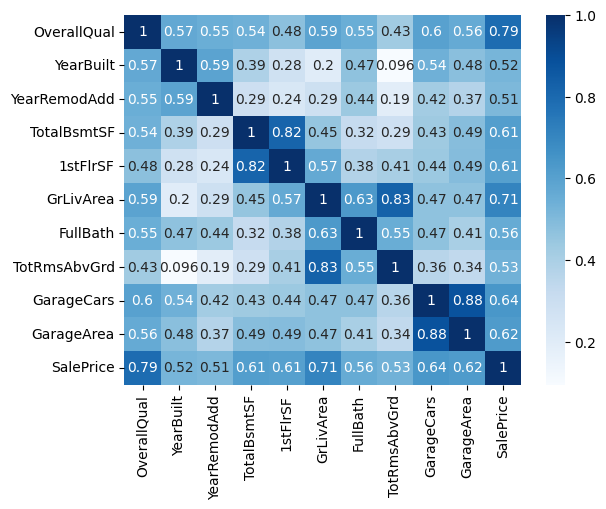

In [91]:
good_corr = []
for i in train.select_dtypes(include=['int', 'float']).columns:
    corr = np.corrcoef(train[i], train['SalePrice'])[0][1]
    if corr > 0.5 and i != 'SalePrice' or corr < -0.5:
        good_corr.append(i)
        print(f'Correlation between {i} and SalePrice is {corr}')
good_corr.append('SalePrice')
train_good_corr = train[good_corr]

sns.heatmap(train_good_corr.corr(), annot=True, cmap='Blues')

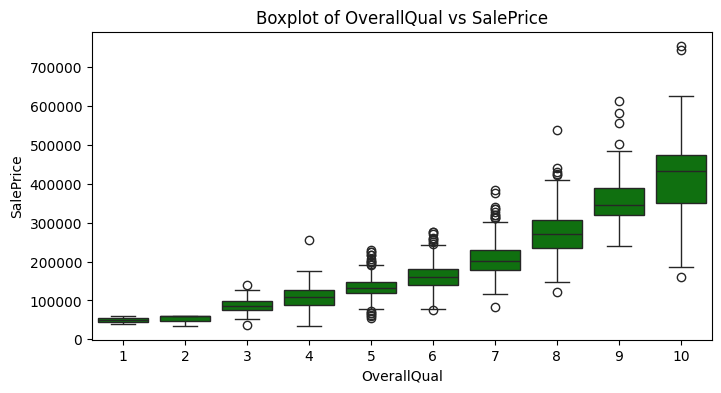

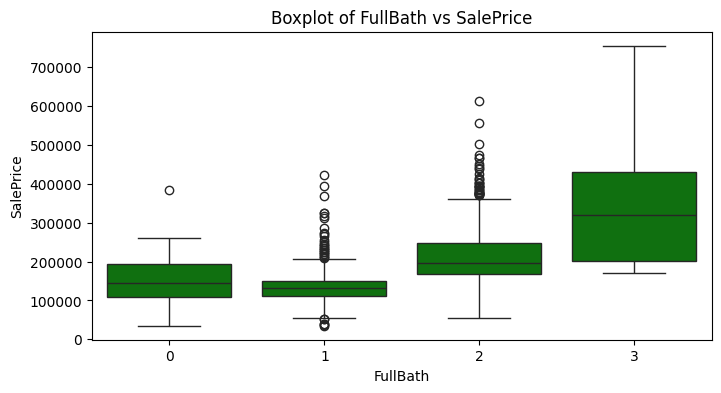

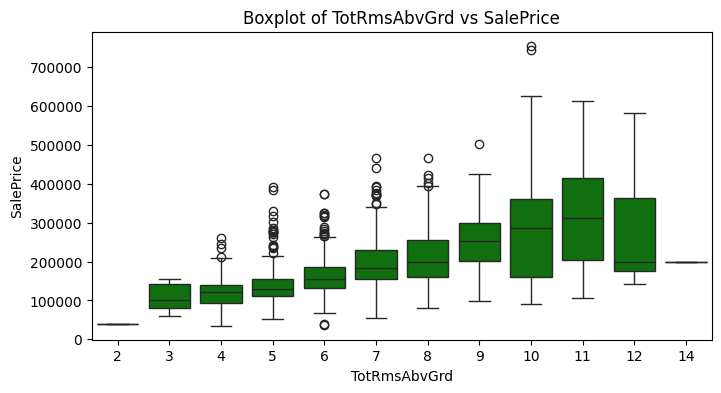

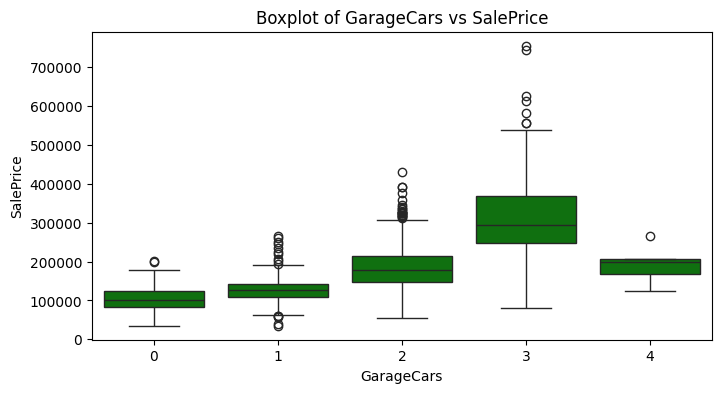

In [92]:

int_good_corr = ['OverallQual', 'FullBath' , 'TotRmsAbvGrd', 'GarageCars']
for i in int_good_corr:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=train[i], y=train['SalePrice'], color = 'green')
    plt.title(f'Boxplot of {i} vs SalePrice')
    plt.show()

In [93]:
droppables = [
    col for col in train.columns 
    if train[col].isna().sum() > 0
    and (len(train) - train[col].isna().sum()) < len(train) / 3 
]
droppables
train = train.drop(columns = droppables)


In [94]:
train.dtypes

Id                 int64
MSSubClass         int64
MSZoning          object
LotFrontage      float64
LotArea            int64
                  ...   
MoSold             int64
YrSold             int64
SaleType          object
SaleCondition     object
SalePrice          int64
Length: 77, dtype: object

In [95]:
class Missing_value_analysis:
    def __init__(self, df, size):
        self.df = df.copy()
        self.size = size
        
    def analysis(self):
        for i in self.df.columns:
            if self.df[i].isna().sum() > 0: 
                print(i + ' has missing values: ' + str(self.df[i].isna().sum()))
            else: 
                pass
        for i in self.df.columns:
            if self.df[i].isna().sum() < self.df.shape[0] * self.size:
                self.df.drop(columns=[i], inplace=True)
            else: pass
        
    def missing_cols(self, cols_to_impute = []):
        for i in self.df.columns:
            if self.df[i].isna().sum() >= self.df.shape[0] * self.size:
                cols_to_impute.append(i)
        
        return(list(cols_to_impute))
        
print(Missing_value_analysis(train, 0.01).analysis())
missing_cols = Missing_value_analysis(train, 0.01).missing_cols()
print(missing_cols)

LotFrontage has missing values: 259
MasVnrType has missing values: 872
MasVnrArea has missing values: 8
BsmtQual has missing values: 37
BsmtCond has missing values: 37
BsmtExposure has missing values: 38
BsmtFinType1 has missing values: 37
BsmtFinType2 has missing values: 38
Electrical has missing values: 1
FireplaceQu has missing values: 690
GarageType has missing values: 81
GarageYrBlt has missing values: 81
GarageFinish has missing values: 81
GarageQual has missing values: 81
GarageCond has missing values: 81
None
['LotFrontage', 'MasVnrType', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageQual', 'GarageCond']


In [96]:
train[missing_cols].isna().sum()

LotFrontage     259
MasVnrType      872
BsmtQual         37
BsmtCond         37
BsmtExposure     38
BsmtFinType1     37
BsmtFinType2     38
FireplaceQu     690
GarageType       81
GarageYrBlt      81
GarageFinish     81
GarageQual       81
GarageCond       81
dtype: int64

In [97]:
class Handling_Numerical_Missing_values:
    def __init__(self, df):
        self.df = df
        self.missing_cols = None  
        self.numeric_missing_cols = None

    def extracting_missing_cols(self):
        # Assuming Missing_value_analysis is defined elsewhere
        self.missing_cols = list(set(Missing_value_analysis(self.df, 0.01).missing_cols()))
        return self.missing_cols

    def copying(self):
        if self.missing_cols is None:
            self.extracting_missing_cols()
        data = self.df[self.missing_cols].copy()
        return data
    
    def getting_numeric_cols(self):
        if self.numeric_missing_cols is None:
            data = self.copying()
            self.numeric_missing_cols = data.select_dtypes(include=['int', 'float']).columns.tolist()
        return self.numeric_missing_cols
    
    def getting_categorical_cols(self):
        data = self.copying()
        categorical_missing_cols = data.select_dtypes(include=['object', 'category']).columns.tolist()
        return categorical_missing_cols
    
    def main(self):
        data = self.copying()
        
        
        for i in self.numeric_missing_cols:
            
            def splitting_feature(data):
                nan_col_name = f'nan_{i}'
                data[nan_col_name] = 0
                data.loc[data[i].isna(), nan_col_name] = 1
                
                trainnum = data[data[nan_col_name] == 0]
                testnum = data[data[nan_col_name] == 1]
                return nan_col_name, trainnum, testnum        
            nan_col_name, trainnum, testnum = splitting_feature(data)
            
            def preparing_feature(nan_col_name, trainnum, testnum):
                xtrain = pd.get_dummies(trainnum.drop(columns=[i, nan_col_name]))
                xtest = pd.get_dummies(testnum.drop(columns=[i, nan_col_name]))
                ytrain = trainnum[i]
                xtest = xtest.reindex(columns=xtrain.columns, fill_value=0) # this is very important, otherwise the indexes of test data will not match of the train data
                return xtrain, xtest, ytrain
            xtrain, xtest, ytrain = preparing_feature(nan_col_name, trainnum, testnum)
            
            def lgbm(xtrain, ytrain, xtest):
                lgbmr = LGBMRegressor(random_state=42, verbose = 1, n_jobs = 1)
                lgbmr.fit(xtrain, ytrain)
                ypred = lgbmr.predict(xtest)
                return ypred
            
            predicted_values = lgbm(xtrain, ytrain, xtest)
            self.df.loc[self.df[i].isna(), i] = predicted_values
# Usage
handler = Handling_Numerical_Missing_values(train)
missing_cols = handler.extracting_missing_cols()  
numeric_missing_cols = handler.getting_numeric_cols()
categorical_missing_cols = handler.getting_categorical_cols()


### Exectuting the final code for numerical missing value imputation
handler.main()
numeric_missing_cols

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000156 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 161
[LightGBM] [Info] Number of data points in the train set: 1201, number of used features: 38
[LightGBM] [Info] Start training from score 70.049958
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000234 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 163
[LightGBM] [Info] Number of data points in the train set: 1379, number of used features: 39
[LightGBM] [Info] Start training from score 1978.506164


['LotFrontage', 'GarageYrBlt']

In [114]:
train[categorical_missing_cols].isna().sum()    

BsmtExposure     38
MasVnrType      872
FireplaceQu     690
GarageType       81
BsmtFinType1     37
GarageQual       81
BsmtCond         37
BsmtQual         37
BsmtFinType2     38
GarageFinish     81
GarageCond       81
dtype: int64

In [99]:
sale = train['SalePrice']
numeric = train.select_dtypes(include=['int', 'float'])

for i in numeric:
    q1 = train[i].quantile(0.25)
    q3 = train[i].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = train[(train[i] < lower_bound) | (train[i] > upper_bound)]
    print(outliers)
    if outliers.empty == 0:
        print(f'{i} has {len(outliers)} outliers')


Empty DataFrame
Columns: [Id, MSSubClass, MSZoning, LotFrontage, LotArea, Street, LotShape, LandContour, Utilities, LotConfig, LandSlope, Neighborhood, Condition1, Condition2, BldgType, HouseStyle, OverallQual, OverallCond, YearBuilt, YearRemodAdd, RoofStyle, RoofMatl, Exterior1st, Exterior2nd, MasVnrType, MasVnrArea, ExterQual, ExterCond, Foundation, BsmtQual, BsmtCond, BsmtExposure, BsmtFinType1, BsmtFinSF1, BsmtFinType2, BsmtFinSF2, BsmtUnfSF, TotalBsmtSF, Heating, HeatingQC, CentralAir, Electrical, 1stFlrSF, 2ndFlrSF, LowQualFinSF, GrLivArea, BsmtFullBath, BsmtHalfBath, FullBath, HalfBath, BedroomAbvGr, KitchenAbvGr, KitchenQual, TotRmsAbvGrd, Functional, Fireplaces, FireplaceQu, GarageType, GarageYrBlt, GarageFinish, GarageCars, GarageArea, GarageQual, GarageCond, PavedDrive, WoodDeckSF, OpenPorchSF, EnclosedPorch, 3SsnPorch, ScreenPorch, PoolArea, MiscVal, MoSold, YrSold, SaleType, SaleCondition, SalePrice]
Index: []

[0 rows x 77 columns]
        Id  MSSubClass MSZoning  LotFron

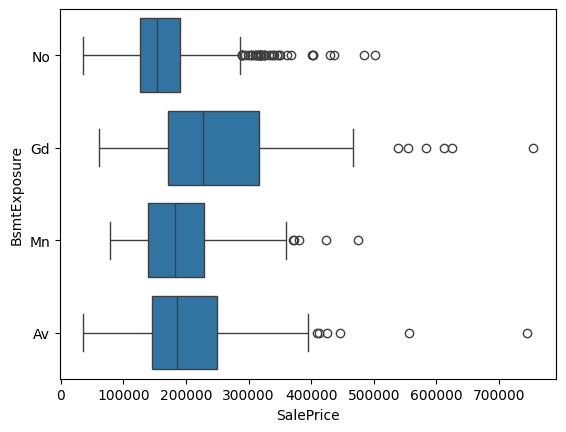

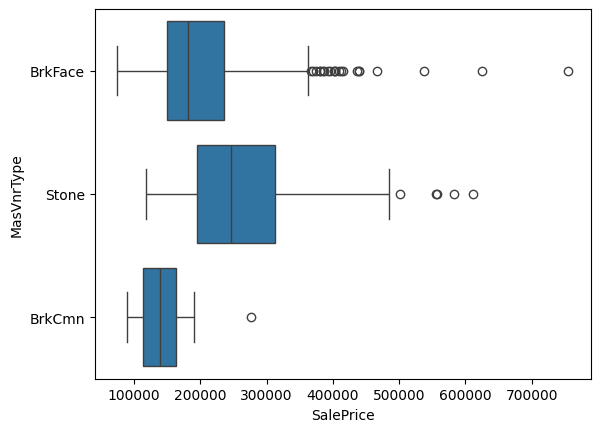

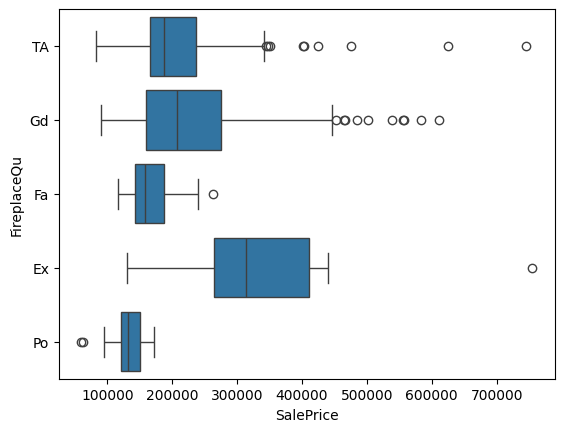

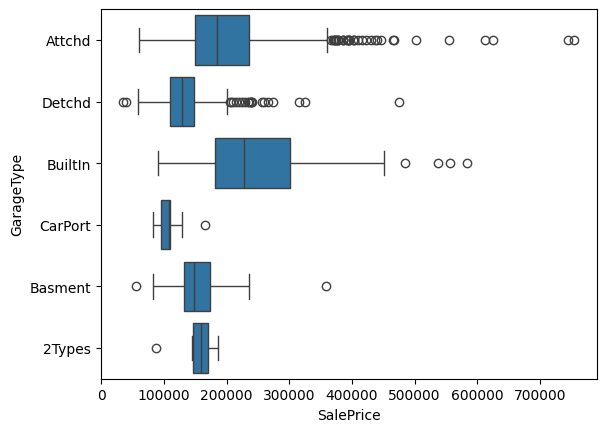

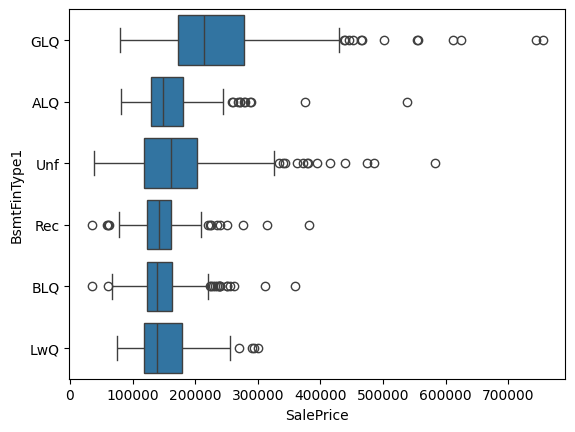

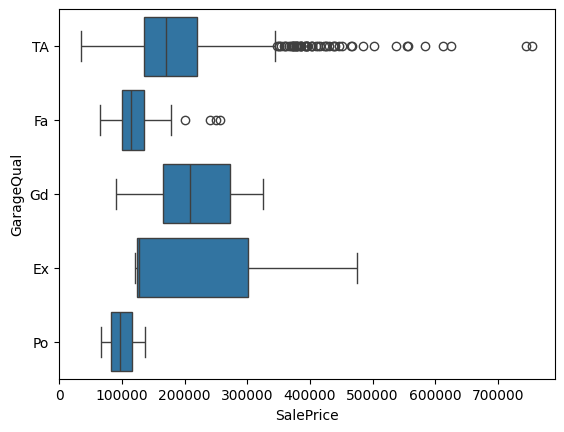

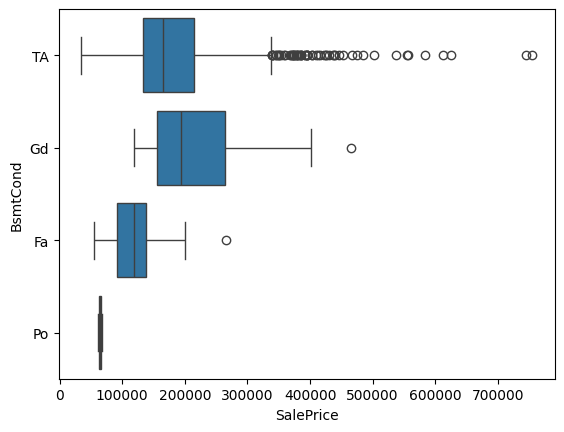

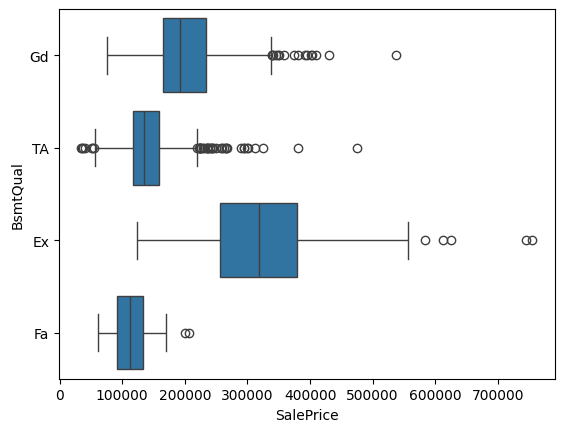

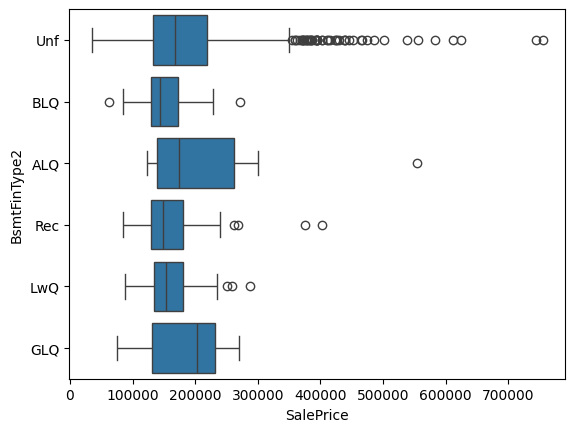

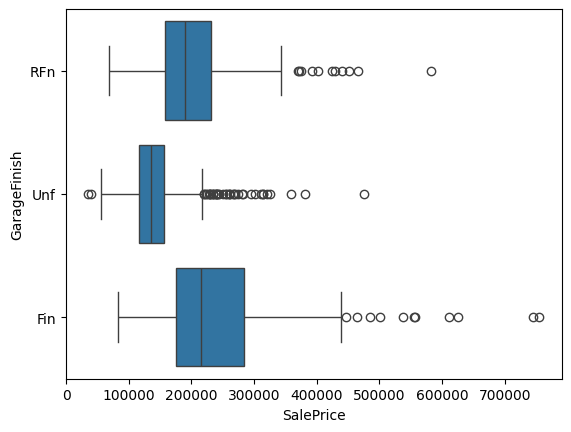

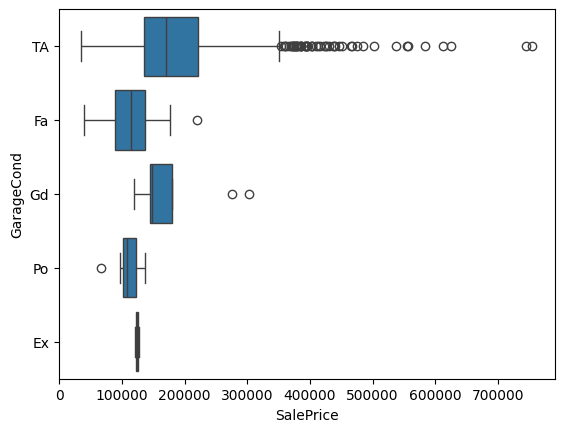

In [100]:
for i in categorical_missing_cols:
    sns.boxplot(y = i, x =sale, data = train)
    plt.show()


In [101]:
for i in categorical_missing_cols:
    each = train[i].value_counts(normalize = True, dropna = True)
    print(each)

BsmtExposure
No    0.670183
Av    0.155415
Gd    0.094233
Mn    0.080169
Name: proportion, dtype: float64
MasVnrType
BrkFace    0.756803
Stone      0.217687
BrkCmn     0.025510
Name: proportion, dtype: float64
FireplaceQu
Gd    0.493506
TA    0.406494
Fa    0.042857
Ex    0.031169
Po    0.025974
Name: proportion, dtype: float64
GarageType
Attchd     0.630892
Detchd     0.280638
BuiltIn    0.063814
Basment    0.013778
CarPort    0.006526
2Types     0.004351
Name: proportion, dtype: float64
BsmtFinType1
Unf    0.302178
GLQ    0.293746
ALQ    0.154603
BLQ    0.104006
Rec    0.093465
LwQ    0.052003
Name: proportion, dtype: float64
GarageQual
TA    0.950689
Fa    0.034808
Gd    0.010152
Ex    0.002175
Po    0.002175
Name: proportion, dtype: float64
BsmtCond
TA    0.921293
Gd    0.045678
Fa    0.031623
Po    0.001405
Name: proportion, dtype: float64
BsmtQual
TA    0.456079
Gd    0.434294
Ex    0.085032
Fa    0.024596
Name: proportion, dtype: float64
BsmtFinType2
Unf    0.883263
Rec    0.037

In [102]:
class Handling_Categorical_Missing_values:
    def __init__(self, df, categorical_missing_cols):
        self.df = df
        self.categorical_missing_cols = categorical_missing_cols
        return df, categorical_missing_cols
    def probabilistic_approach(self):
        
        imputations = []
        for m in range(len(categorical_missing_cols)):
            data = self.df.copy()
            for col in data.select_dtypes(include=['object']):
                probs = data[col].value_counts(normalize = True)

In [103]:
X = pd.get_dummies(train.drop(columns=['SalePrice']))
y = train['SalePrice']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

<Axes: xlabel='SalePrice', ylabel='Density'>

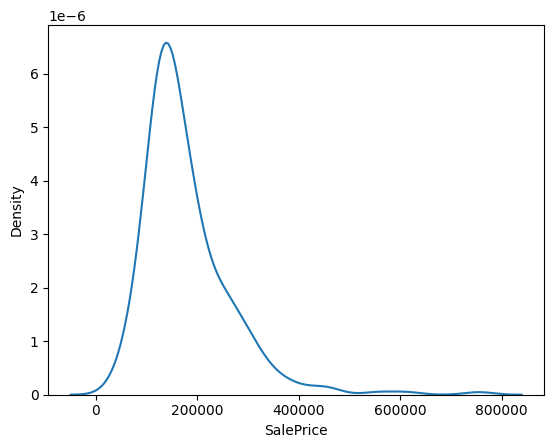

In [104]:
sns.kdeplot(y_test)

 Mean Absolute Error: 17775.001771037463


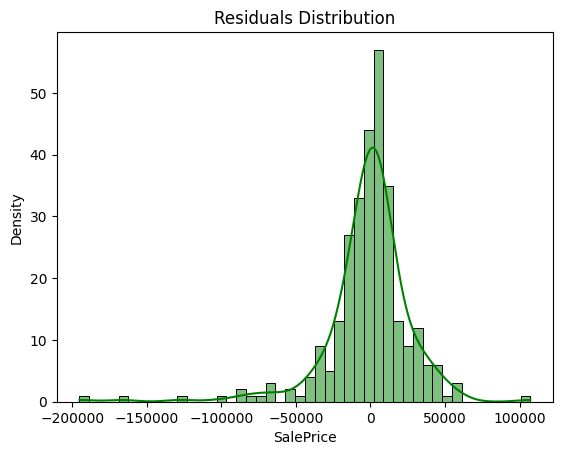

In [105]:
random_forest = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1, min_samples_split=5, min_samples_leaf=2, max_depth=1000)
random_forest.fit(X_train, y_train)
rf_pred = random_forest.predict(X_test)
print(f' Mean Absolute Error: {mean_absolute_error(y_test, rf_pred)}')
sns.histplot(rf_pred - y_test, kde=True, color = 'green')
plt.title('Residuals Distribution')
plt.ylabel('Density')
plt.show()

 Mean Absolute Error: 26658.873867422477


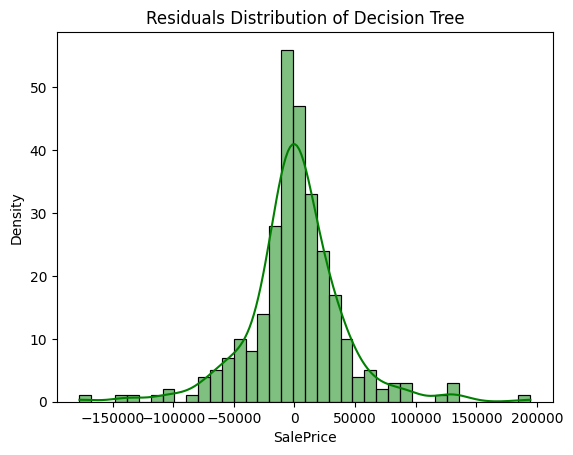

In [106]:
decision_tree = DecisionTreeRegressor(random_state=42, max_depth=10, min_samples_split=5, min_samples_leaf=2)
decision_tree.fit(X_train, y_train)
decision_tree_pred = decision_tree.predict(X_test)
print(f' Mean Absolute Error: {mean_absolute_error(y_test, decision_tree_pred)}')
sns.histplot(decision_tree_pred - y_test, kde=True, color = 'green')
plt.title('Residuals Distribution of Decision Tree')
plt.ylabel('Density')
plt.show()

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000958 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3593
[LightGBM] [Info] Number of data points in the train set: 1168, number of used features: 174
[LightGBM] [Info] Start training from score 181441.541952
 Mean Absolute Error: 17089.372822371206


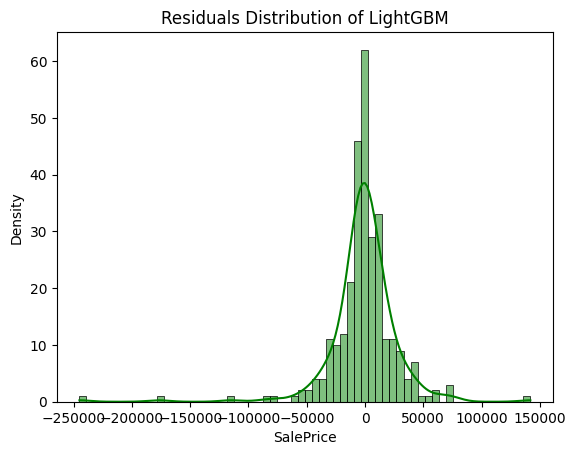

In [107]:
lgbm = LGBMRegressor(random_state=42)
lgbm.fit(X_train, y_train)
lgbm_pred = lgbm.predict(X_test)
print(f' Mean Absolute Error: {mean_absolute_error(y_test, lgbm_pred)}')
sns.histplot(lgbm_pred - y_test, kde=True, color = 'green')
plt.title('Residuals Distribution of LightGBM')
plt.ylabel('Density')
plt.show()

 Mean Absolute Error: 15774.41796875


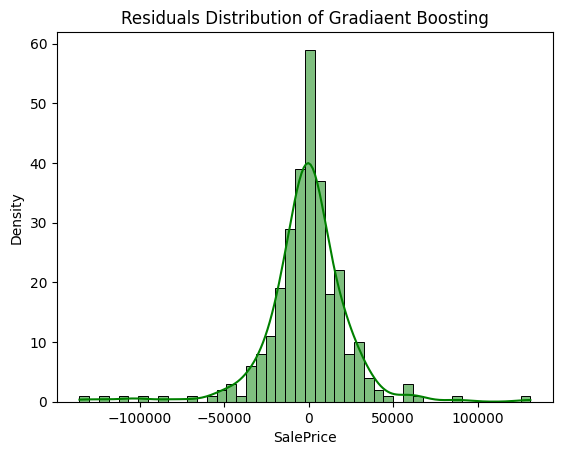

In [108]:
xgb_train = xgb.DMatrix(X_train, y_train, enable_categorical=True)
xgb_test = xgb.DMatrix(X_test, y_test, enable_categorical=True)
params = {
    'objective': 'reg:squarederror',
    'eval_metric': 'mae',
    'learning_rate': 0.1,
    'max_depth': 5,
    'seed': 42
}

num_boost_round = 100
xgb_model = xgb.train(params, xgb_train, num_boost_round)

xgb_pred = xgb_model.predict(xgb_test)

print(f' Mean Absolute Error: {mean_absolute_error(y_test, xgb_pred)}')
sns.histplot(xgb_pred - y_test, kde=True, color = 'green')
plt.title('Residuals Distribution of Gradiaent Boosting')
plt.ylabel('Density')
plt.show()

In [109]:
tf_model = keras.Sequential([
    # Input layer. The shape must match the number of features in our data (10).
    layers.Input(shape=(X_train.shape[1],)),
    # First hidden layer with 64 neurons
    layers.Dense(64, activation='relu'),
    # Second hidden layer with 32 neurons
    layers.Dense(32, activation='relu'),
    # Output layer with a single neuron to predict the house price
    layers.Dense(1)
])

tf_model.compile(optimizer='adam', loss='mean_absolute_error')

In [110]:
tf_model.fit(X_train, y_train, epochs=2, batch_size=32, validation_split=0.2, verbose=1)

Epoch 1/2
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 181481.0000 - val_loss: 181102.1562
Epoch 2/2
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 181526.3906 - val_loss: 181102.0469


In [111]:
tf_pred = tf_model.predict(X_test)
print(mean_absolute_error(y_test, tf_pred))

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
178839.609375


In [112]:
test = pd.read_csv(r'D:\House Price prediction\test.csv')

test.head(2)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal


In [116]:
cols = train.columns.intersection(test.columns)
test = test[cols]
test.head(2)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,LotShape,LandContour,Utilities,LotConfig,...,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,Reg,Lvl,AllPub,Inside,...,0,0,0,120,0,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,IR1,Lvl,AllPub,Corner,...,36,0,0,0,0,12500,6,2010,WD,Normal


In [121]:
X_train.head(2)

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
254,255,20,70.0,8400,5,6,1957,1957,0.0,922,...,False,False,False,True,False,False,False,False,True,False
1066,1067,60,59.0,7837,6,7,1993,1994,0.0,0,...,False,False,False,True,False,False,False,False,True,False


In [123]:
from sklearn.neighbors import KNeighborsRegressor 

In [124]:
neighbors = np.arange(1, 21)
for i in neighbors:
    model = KNeighborsRegressor(n_neighbors=i)
    model.fit(train.drop(columns = ['SalePrice']), train['SalePrice'])
    knn_pred = model.predict(X_test)
    print(f'For {i} neighbors, Mean Absolute Error: {mean_absolute_error(y_test, knn_pred)}')

ValueError: could not convert string to float: 'RL'